# Allan Variance of Stock Prices

The Allan variance, originally developed for characterizing clock stability, can reveal the nature of noise in any time series. Applied to stock prices, it shows how price volatility scales with the observation interval $\tau$.

For a signal $y(t)$ sampled at interval $\tau_0$, the Allan variance at averaging time $\tau = n\tau_0$ is:

$$\sigma^2_A(\tau) = \frac{1}{2} \left\langle \left( \bar{y}_{k+1} - \bar{y}_k \right)^2 \right\rangle$$

where $\bar{y}_k$ is the average of $y$ over the $k$-th interval of length $\tau$.

On a log-log plot:
- Slope $-1$ → white noise (independent daily fluctuations)
- Slope $0$ → flicker noise (correlated trends)
- Slope $+1$ → random walk

In [8]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u

from freqandsee.freqandsee import (
    StockSignal,
    AllanFilter,
    FilterBank,
    FlexibleSignal,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Fetch stock data

Pull 2 years of closing prices so we have enough data for longer averaging times.

In [9]:
tickers = ["AAPL", "MSFT", "GOOGL", "SHIP", "VTI", "PDD"]
stocks = {t: StockSignal(t, column="Close", period="3y") for t in tickers}

for t, s in stocks.items():
    print(f"{t:6s} {s.n} days")

AAPL   1095 days
MSFT   1095 days
GOOGL  1095 days
SHIP   1095 days
VTI    1095 days
PDD    1095 days


## Build Allan filter bank

Create Allan filters with geometrically increasing averaging times: 2, 4, 8, 16, ... days. Each filter computes the Allan deviation at that timescale.

In [10]:
# Averaging times: 2, 4, 8, ..., 128 days
max_exponent = 7  # 2^7 = 128 days
n_values = [2**k for k in range(1, max_exponent + 1)]

filter_bank = FilterBank(
    filters=[AllanFilter(n=n) for n in n_values],
    name="Allan filter bank",
)

tau_days = np.array([n for n in n_values])
print(f"Averaging times (days): {tau_days}")

Averaging times (days): [  2   4   8  16  32  64 128]


## Compute Allan deviation for each stock

Filter each stock signal through the Allan filter bank. The RMS of each filtered signal gives the Allan deviation $\sigma_A(\tau)$ at that averaging time.

In [11]:
def compute_allan_dev(stock_signal, filter_bank):
    """Compute Allan deviation at each tau from the filter bank."""
    bundle = stock_signal * filter_bank
    return np.array([signal.rms.value for signal in bundle])

adevs = {t: compute_allan_dev(s, filter_bank) for t, s in stocks.items()}

for t, adev in adevs.items():
    print(f"{t:6s} Allan dev: {[f'{v:.2f}' for v in adev]}")

AAPL   Allan dev: ['3.46', '4.77', '6.58', '9.04', '12.83', '18.97', '27.47']
MSFT   Allan dev: ['5.96', '8.06', '11.24', '15.82', '23.08', '34.15', '48.81']
GOOGL  Allan dev: ['2.55', '3.53', '4.94', '7.04', '10.35', '16.40', '24.76']
SHIP   Allan dev: ['0.13', '0.18', '0.27', '0.40', '0.55', '0.69', '1.02']
VTI    Allan dev: ['3.83', '5.19', '7.20', '10.15', '14.40', '20.84', '30.66']
PDD    Allan dev: ['2.24', '3.24', '4.66', '6.33', '7.81', '10.06', '13.93']


## Allan deviation plot

Log-log plot of Allan deviation vs averaging time $\tau$. Reference slopes are shown for white noise ($\tau^{-1/2}$) and random walk ($\tau^{+1/2}$).

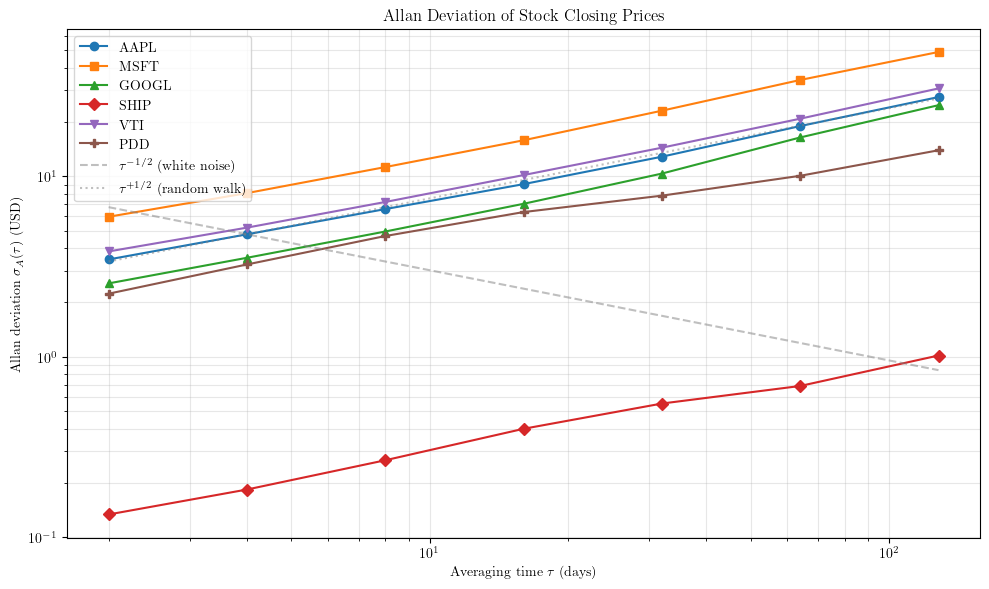

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

markers = ["o", "s", "^", "D", "v", "P"]
for (t, adev), marker in zip(adevs.items(), markers):
    ax.loglog(tau_days, adev, f"{marker}-", label=t)

# Reference slopes anchored to first stock at tau=4
anchor = list(adevs.values())[0][1]
ref_tau = np.array([2, 128])
ax.loglog(
    ref_tau,
    anchor * (ref_tau / 4) ** (-0.5),
    "--", color="gray", alpha=0.5, label=r"$\tau^{-1/2}$ (white noise)",
)
ax.loglog(
    ref_tau,
    anchor * (ref_tau / 4) ** (0.5),
    ":", color="gray", alpha=0.5, label=r"$\tau^{+1/2}$ (random walk)",
)

ax.set_xlabel(r"Averaging time $\tau$ (days)")
ax.set_ylabel(r"Allan deviation $\sigma_A(\tau)$ (USD)")
ax.set_title("Allan Deviation of Stock Closing Prices")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Normalized Allan deviation

To compare volatility characteristics across stocks with different price levels, normalize the Allan deviation by the mean price. This gives a dimensionless relative measure.

<>:9: SyntaxWarning: invalid escape sequence '\$'
<>:9: SyntaxWarning: invalid escape sequence '\$'
/var/folders/kp/7bb_53v50n55zgjwcdhs38_8_rxdd8/T/ipykernel_245/2973589896.py:9: SyntaxWarning: invalid escape sequence '\$'
  label=f"{t} (mean \${mean_price:.0f})",


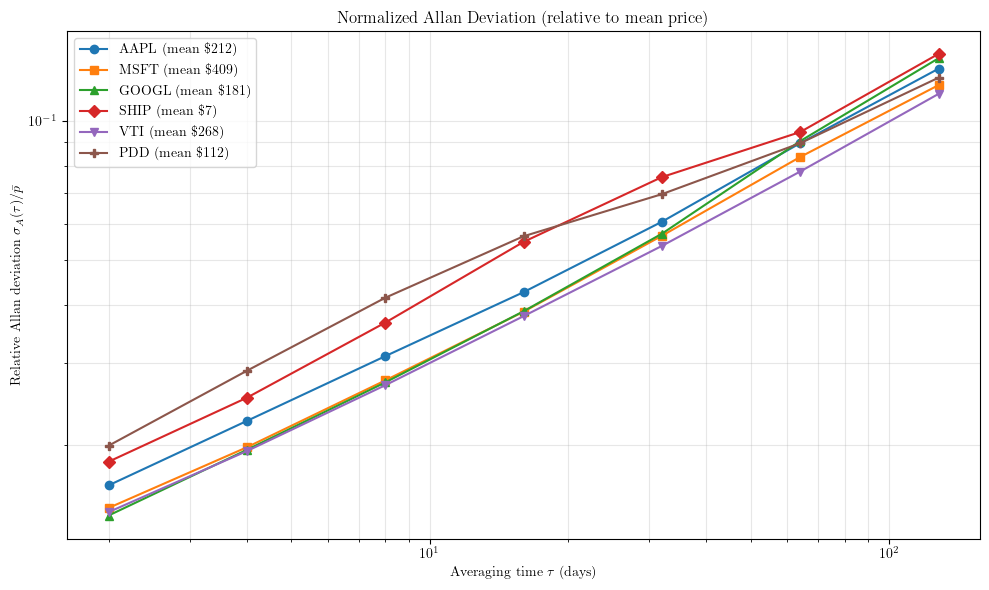

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

for (t, adev), marker in zip(adevs.items(), markers):
    mean_price = stocks[t].mean.value
    ax.loglog(
        tau_days,
        adev / mean_price,
        f"{marker}-",
        label=f"{t} (mean \${mean_price:.0f})",
    )

ax.set_xlabel(r"Averaging time $\tau$ (days)")
ax.set_ylabel(r"Relative Allan deviation $\sigma_A(\tau) / \bar{p}$")
ax.set_title("Normalized Allan Deviation (relative to mean price)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Filtered signals at different timescales

Visualize what the Allan filter actually does: it extracts fluctuations at each averaging timescale.

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'AAPL Allan-filtered'}, xlabel='x(AAPL Close (interpolated 1.0 1 / d) * 64-day) ($\\mathrm{d}$)', ylabel='y(AAPL Close (interpolated 1.0 1 / d) * 64-day) ($\\mathrm{USD}$)'>)

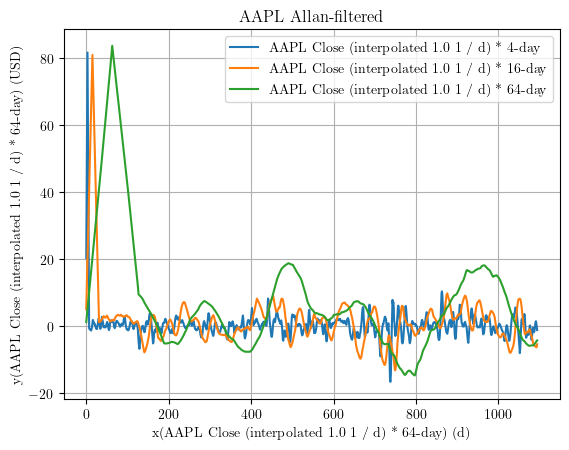

In [14]:
from freqandsee.freqandsee import SignalBundle, USD

# Pick a few representative timescales for AAPL
aapl = stocks["AAPL"]
short = aapl * AllanFilter(n=4, name="4-day")
medium = aapl * AllanFilter(n=16, name="16-day")
long = aapl * AllanFilter(n=64, name="64-day")

bundle = SignalBundle([short, medium, long], name="AAPL Allan-filtered")
bundle.plot(
    all_in_one=True,
    x_display_unit=u.day,
    y_display_unit=USD,
)